# Tutorial 2 · Microglia in Alzheimer's disease
Two amyloid models (paper Fig. 5), with the default Niche-FATE weights:
**A.** Xenium, TgCRND8 at 2.5, 5.7 and 17.9 months and wild type at 2.5, 5.7 and 13.4 months: which homeostatic microglia become DAM,
and which received signals are associated with this.
**B.** STARmap PLUS, TauPS2APP and control at 8 and 13 months (2 mice each): homeostatic microglia that become DAM, DAM that return to
the homeostatic state, and how both relate to amyloid plaques.
Received signals were pre-computed with CytoSignal (`obsm['cytosignal']`, ligand-receptor pairs). All sections of a study share one
microglia state space.

In [1]:
import anndata as ad, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import nichefate as nf
DATA = "../tutorial_data/"
MG = ["homeostatic", "DAM"]; MG3 = MG + ["BAM-like"]
COL = {"homeostatic": "#3a6db5", "DAM": "#c8553d"}

## A · Xenium: homeostatic → DAM

347 shared genes, 13 ligand-receptor pairs, 13 signals (pair)


D:\Niche-FATE\nichefate\_gnn.py:14: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  At = torch.sparse_coo_tensor(np.vstack([A.row, A.col]), A.data.astype(np.float32), A.shape, device=device).coalesce()


niche computed for 6 sections: [53328, 58026, 59392, 58167, 58583, 58597] cells


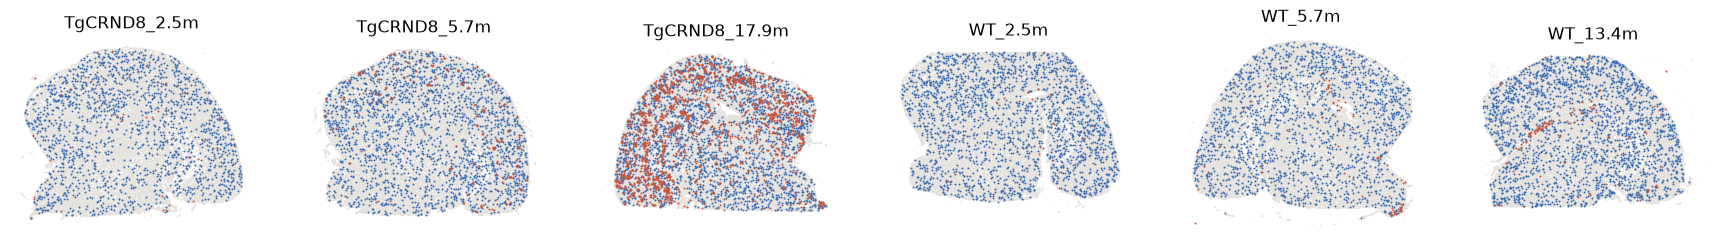

In [2]:
TG = ["TgCRND8_2.5m", "TgCRND8_5.7m", "TgCRND8_17.9m"]; WT = ["WT_2.5m", "WT_5.7m", "WT_13.4m"]
tg = [ad.read_h5ad(DATA + f"ad_{s}.h5ad") for s in TG]; wt = [ad.read_h5ad(DATA + f"ad_{s}.h5ad") for s in WT]
allX = tg + wt
nf.compute_niche(allX, level="pair", signals=[pd.DataFrame(x.obsm["cytosignal"], index=x.obs_names, columns=x.uns["cytosignal_names"]) for x in allX],
                 target_sum=100, n_sub=150_000)
fig, ax = plt.subplots(1, 6, figsize=(22, 4))
for a, s, x in zip(ax, TG + WT, tg + wt):
    nf.pl.groups_map(x, "state", ax=a, s=2, order=MG, colors=COL); a.set_title(s); a.get_legend().remove()
plt.show()

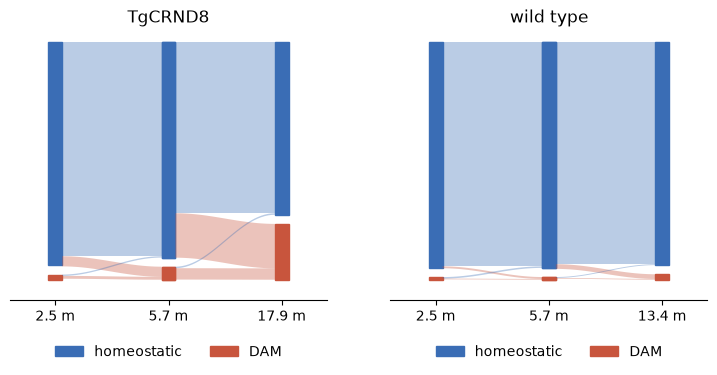

,TgCRND8,wild type
early,0.045,0.009
late,0.204,0.020


In [3]:
kw = dict(groupby="state", cells1=MG3, cells2=MG3, pca_sections=allX, pca_cells=[x.obs.state.isin(MG3).values for x in allX], scale_signals=False)
res_tg = [nf.match(tg[i], tg[i + 1], **kw) for i in range(2)]
res_wt = [nf.match(wt[i], wt[i + 1], **kw) for i in range(2)]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
nf.pl.sankey(res_tg, MG, labels=["2.5 m", "5.7 m", "17.9 m"], colors=COL, ax=ax[0]); ax[0].set_title("TgCRND8")
nf.pl.sankey(res_wt, MG, labels=["2.5 m", "5.7 m", "13.4 m"], colors=COL, ax=ax[1]); ax[1].set_title("wild type"); plt.show()
pd.DataFrame({"TgCRND8": [r.transitions.loc["homeostatic", "DAM"] for r in res_tg], "wild type": [r.transitions.loc["homeostatic", "DAM"] for r in res_wt]},
             index=["early", "late"]).round(3)

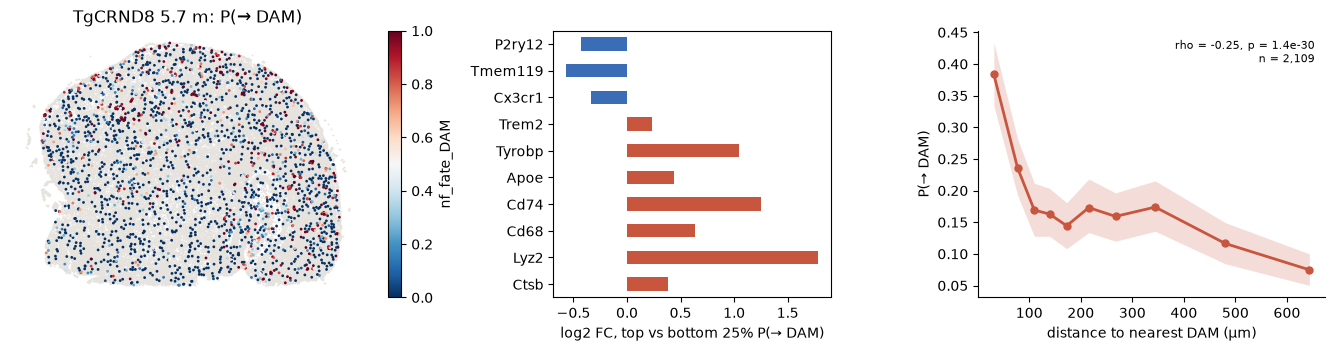

In [4]:
x = tg[1]; p = nf.fate(res_tg[1], "DAM", among=MG)
h = x.obs.state.values[res_tg[1].idx1] == "homeostatic"; ph = p[h]
genes = ["P2ry12", "Tmem119", "Cx3cr1", "Trem2", "Tyrobp", "Apoe", "Cd74", "Cd68", "Lyz2", "Ctsb"]
L = pd.DataFrame(x[ph.index, genes].layers["nf_lognorm"].toarray(), index=ph.index, columns=genes)
top, bot = ph >= ph.quantile(0.75), ph <= ph.quantile(0.25)
lfc = np.log2((L[top].mean() + 0.01) / (L[bot].mean() + 0.01))
dDAM = cKDTree(x.obsm["spatial"][x.obs.state.values == "DAM"]).query(x[ph.index].obsm["spatial"])[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.3, 0.8, 1]))
nf.pl.fate_map(x, "nf_fate_DAM", ax=ax[0], s=4, title="TgCRND8 5.7 m: P(→ DAM)")
lfc[::-1].plot.barh(ax=ax[1], color=[COL["DAM"] if v > 0 else COL["homeostatic"] for v in lfc[::-1]]); ax[1].set_xlabel("log2 FC, top vs bottom 25% P(→ DAM)")
nf.pl.binned(dDAM, ph.values, n_bins=10, ax=ax[2], xlabel="distance to nearest DAM (µm)", ylabel="P(→ DAM)")
plt.tight_layout(); plt.show()

### Signals associated with conversion
Partial rank correlation with P(→ DAM), adjusted for each cell's own state, local density and the local share of neurons;
P values from spatial block permutation.

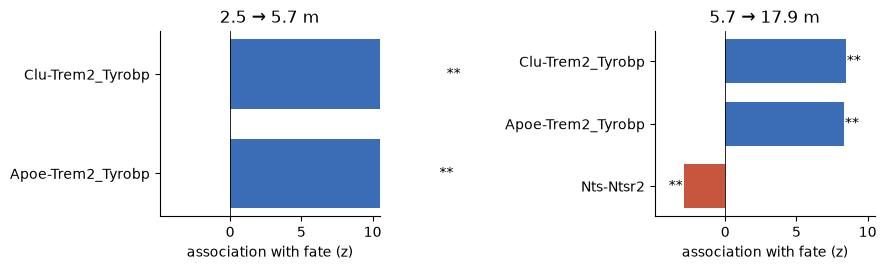

,signal,r,z,p,q,stable,detect
0,Clu-Trem2_Tyrobp,0.1861,8.4599,0.0005,0.0017,True,0.3882
1,Apoe-Trem2_Tyrobp,0.1830,8.3288,0.0005,0.0017,True,0.3882
2,Cdh6-Cdh6,0.0068,0.2748,0.7521,0.8146,False,0.2232
3,Pecam1-Pecam1,0.0051,0.2189,0.8146,0.8146,True,0.6534
4,Cdh4-Cdh4,-0.0355,-1.5498,0.1249,0.1749,True,0.3078
5,Aldh1a2-Rorb,-0.0439,-1.8971,0.0615,0.1076,False,0.3320
6,Nts-Ntsr2,-0.0637,-2.9068,0.0030,0.0070,True,0.1483


In [5]:
for x in tg:
    x.obs["neuron"] = np.where(x.obs.cell_type.isin(["ExN", "InN"]), "neuron", "other")
dx = [nf.drivers(r, nf.fate(r, "DAM", among=MG), cells=["homeostatic"], composition_key="neuron", celltype_key="cell_type", min_detect=0.10, n_perm=2000) for r in res_tg]
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8), sharex=True)
for a, d, t in zip(ax, dx, ["2.5 → 5.7 m", "5.7 → 17.9 m"]):
    nf.pl.drivers(d, ax=a); a.set_title(t)
plt.tight_layout(); plt.show()
dx[1].round(4)

## B · STARmap PLUS: conversion and reversion

2766 shared genes, 439 ligand-receptor pairs, 127 signals (pathway)


niche computed for 8 sections: [8186, 10372, 8202, 9634, 8506, 8034, 9803, 9428] cells


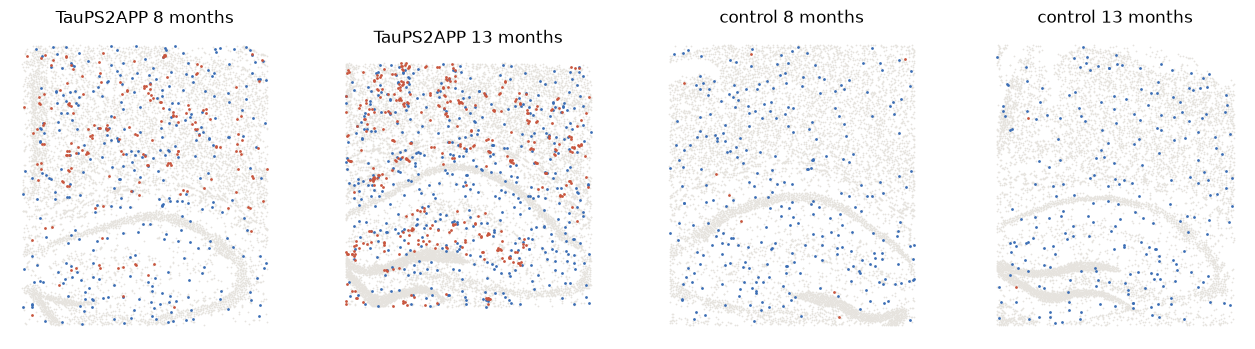

In [6]:
S = {(g, r, t): ad.read_h5ad(DATA + f"starmap_{g}_r{r}_{t}m.h5ad") for g in ("TauPS2APP", "control") for r in (1, 2) for t in (8, 13)}
allS = list(S.values())
nf.compute_niche(allS, signals=[pd.DataFrame(x.obsm["cytosignal"].astype(float), index=x.obs_names, columns=x.uns["cytosignal_pairs"]) for x in allS])
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, k in zip(ax, [("TauPS2APP", 1, 8), ("TauPS2APP", 1, 13), ("control", 1, 8), ("control", 1, 13)]):
    nf.pl.groups_map(S[k], "state", ax=a, s=4, order=MG, colors=COL); a.set_title(f"{k[0]} {k[2]} months"); a.get_legend().remove()
plt.show()

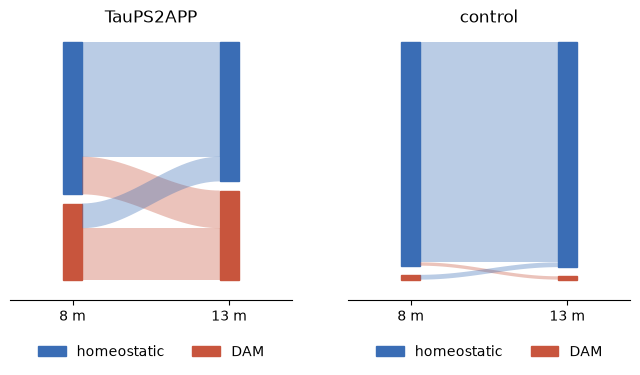

,homeostatic,DAM
homeostatic,0.753,0.247
DAM,0.324,0.676


In [7]:
R = {(g, a, b): nf.match(S[g, a, 8], S[g, b, 13], groupby="state", cells1=MG, cells2=MG, pca_sections=allS, scale_signals=False)
     for g in ("TauPS2APP", "control") for a in (1, 2) for b in (1, 2)}
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, g in zip(ax, ("TauPS2APP", "control")):
    nf.pl.sankey([[R[g, i, j] for i in (1, 2) for j in (1, 2)]], MG, labels=["8 m", "13 m"], colors=COL, ax=a); a.set_title(g)
plt.show()
(sum(R["TauPS2APP", i, j].transitions.loc[MG, MG] for i in (1, 2) for j in (1, 2)) / 4).round(3)

### Fates and distance to amyloid plaques
Plaque positions are not used by the model. The numbers on the plots are unadjusted Spearman correlations; the paper (Fig. 5h)
reports the association adjusted for each cell's own expression state and local density.

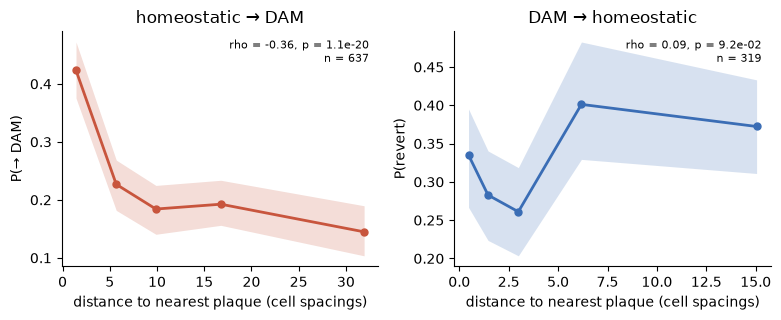

In [8]:
def avg(a, target):                   # each 8-month section is matched to both 13-month sections of its genotype
    return (nf.fate(R["TauPS2APP", a, 1], target, among=MG) + nf.fate(R["TauPS2APP", a, 2], target, among=MG)) / 2
pdam = {a: avg(a, "DAM") for a in (1, 2)}; prev = {a: avg(a, "homeostatic") for a in (1, 2)}
hp, hd, rp, rd = [], [], [], []
for a in (1, 2):
    o = S["TauPS2APP", a, 8].obs.loc[pdam[a].index]; h = (o.state == "homeostatic").values
    hp.append(pdam[a][h].values); hd.append(o.plaque_dist.values[h])
    rp.append(prev[a][~h].values); rd.append(o.plaque_dist.values[~h])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.3))
nf.pl.binned(np.concatenate(hd), np.concatenate(hp), ax=ax[0], color=COL["DAM"], xlabel="distance to nearest plaque (cell spacings)", ylabel="P(→ DAM)")
nf.pl.binned(np.concatenate(rd), np.concatenate(rp), ax=ax[1], color=COL["homeostatic"], xlabel="distance to nearest plaque (cell spacings)", ylabel="P(revert)")
ax[0].set_title("homeostatic → DAM"); ax[1].set_title("DAM → homeostatic"); plt.tight_layout(); plt.show()

### Genes that differ between reverting and remaining DAM

In [9]:
from scipy.stats import mannwhitneyu
X, rev = [], []
for a in (1, 2):
    x = S["TauPS2APP", a, 8]; o = x.obs.loc[prev[a].index]; dam = (o.state == "DAM").values
    X.append(x[o.index[dam]].layers["nf_lognorm"].toarray()); rev.append(prev[a].values[dam] > 0.5)
X, rev = np.vstack(X), np.concatenate(rev); genes = np.asarray(S["TauPS2APP", 1, 8].var_names)
keep = np.maximum((X[rev] > 0).mean(0), (X[~rev] > 0).mean(0)) >= 0.1      # genes detected in >= 10% of either group
E = np.expm1(X)
de = pd.DataFrame({"gene": genes[keep],
                   "log2fc": np.log2((E[rev][:, keep].mean(0) + 1e-9) / (E[~rev][:, keep].mean(0) + 1e-9)),
                   "p": [mannwhitneyu(X[rev, j], X[~rev, j]).pvalue for j in np.flatnonzero(keep)]})
print(rev.sum(), "reverting and", (~rev).sum(), "remaining DAM;", len(de), "genes tested")
de.sort_values("p").head(10).round(4)

85 reverting and 234 remaining DAM; 287 genes tested


,gene,log2fc,p
235,Sgip1,3.2118,0.0000
128,Hs3st2,1.9009,0.0001
209,Rab6b,1.3126,0.0002
152,Lyz2,-1.3309,0.0009
69,Ctsb,-0.6220,0.0014
86,Dnm1,1.0531,0.0027
28,Blnk,1.4624,0.0027
14,Apoe,-0.4499,0.0036
168,Ndrg2,0.7588,0.0041
99,Fbn2,-4.2811,0.0045


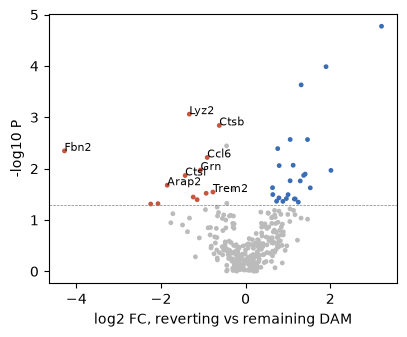

In [10]:
sig = (de.p < 0.05) & (de.log2fc.abs() > 0.5)
col = np.where(sig & (de.log2fc > 0), COL["homeostatic"], np.where(sig, COL["DAM"], "#bbbbbb"))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.scatter(de.log2fc, -np.log10(de.p), s=6, c=col)
for _, r in de[sig & (de.log2fc < 0)].nsmallest(8, "p").iterrows():      # label genes higher in remaining DAM
    ax.annotate(r.gene, (r.log2fc, -np.log10(r.p)), fontsize=8)
ax.axhline(-np.log10(0.05), color="grey", lw=0.5, ls="--")
ax.set_xlabel("log2 FC, reverting vs remaining DAM"); ax.set_ylabel("-log10 P"); plt.show()